# 9. Evaluación de los modelos de clasificación

Dos niveles de evaluación:

1. **Validación anidada (bucle externo).** Las 112 combinaciones, media ± desviación estándar en los
   5 pliegues externos. Con ella se elige la mejor combinación de cada modelo (sin mirar la prueba).
2. **Prueba (octubre–diciembre, establecimientos no vistos, 127.391 casos).** Cada combinación se
   reajusta en toda la submuestra de desarrollo con sus hiperparámetros finales y se evalúa una vez.

La prueba ya se había usado en los entregables 1 y 2 para reportar la regresión logística; no es
una prueba virgen (ver límites en el capítulo de conclusiones).

In [1]:
import sys, json, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, classification_report
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from osha_e3 import config as C, data as D, models as M, nested as N, final as F, evaluation as E, plots as P, search as S, cache
P.setup()
mc = N.master_table('clf'); tc = F.test_table('clf')
test, yt = F.test_data('clf')
OPTS, BALS, MODELS = M.OPTIMIZERS, M.BALANCES, P.MODEL_ORDER_CLF
mc['label'] = mc.model.map(M.PRETTY) + ' · ' + mc.balance.map(M.PRETTY) + ' · ' + mc.optimizer.map(M.PRETTY)
fmt = lambda m, s: f'{m:.3f} ± {s:.3f}'

## 9.1 Las 112 combinaciones en la validación anidada

Tabla maestra completa: `results/master_clf.csv` (una fila por combinación, con hiperparámetros
finales, métricas externas, tiempos y semilla). Aquí, las 15 mejores por balanced accuracy externa.

*Nota de medición.* Durante la corrida, el AUC del bucle externo se calculó después de recortar las
probabilidades a 10⁻¹² y renormalizarlas, lo que rompe los empates de los modelos que dan muchas
probabilidades exactamente 0 (KNN y el árbol). Eso subestima su AUC externo en torno a 0,005 a 0,015
(en la prueba: KNN 0,620 frente a 0,624; árbol 0,613 frente a 0,628). Las demás métricas no se ven
afectadas. Desde la sección 9.2 todas las AUC de la prueba usan el cálculo corregido.

In [2]:
cols = ['recall', 'f1', 'auc', 'accuracy', 'precision', 'brier', 'ece']
top = mc.sort_values('outer_recall_mean', ascending=False).head(15)
pd.DataFrame({'Combinación': top.label,
              **{c: [fmt(a, b) for a, b in zip(top[f'outer_{c}_mean'], top[f'outer_{c}_std'])] for c in cols}}
             ).rename(columns={'recall': 'Balanced acc. (recall macro)', 'f1': 'F1 macro', 'auc': 'AUC macro',
                               'accuracy': 'Accuracy', 'precision': 'Precision macro', 'brier': 'Brier', 'ece': 'ECE'}).set_index('Combinación')

,Balanced acc. (recall macro),F1 macro,AUC macro,Accuracy,Precision macro,Brier,ECE
Combinación,,,,,,,
SVM · SMOTE · Random,0.469 ± 0.101,0.368 ± 0.025,0.712 ± 0.051,0.492 ± 0.037,0.389 ± 0.017,0.632 ± 0.028,0.096 ± 0.040
SVM · ADASYN · Random,0.463 ± 0.108,0.361 ± 0.032,0.705 ± 0.055,0.485 ± 0.041,0.382 ± 0.024,0.636 ± 0.027,0.095 ± 0.037
Árbol · class_weight · Bayesiana (TPE),0.461 ± 0.084,0.334 ± 0.015,0.660 ± 0.052,0.444 ± 0.029,0.373 ± 0.024,0.667 ± 0.033,0.092 ± 0.023
SVM · ADASYN · Genética,0.457 ± 0.104,0.356 ± 0.039,0.698 ± 0.069,0.479 ± 0.053,0.384 ± 0.026,0.636 ± 0.032,0.090 ± 0.035
SVM · ADASYN · Grid,0.457 ± 0.099,0.357 ± 0.035,0.695 ± 0.070,0.477 ± 0.052,0.386 ± 0.019,0.642 ± 0.037,0.094 ± 0.034
SVM · ADASYN · Bayesiana (TPE),0.445 ± 0.108,0.350 ± 0.039,0.693 ± 0.075,0.467 ± 0.059,0.382 ± 0.024,0.646 ± 0.040,0.093 ± 0.030
SVM · SMOTE · Grid,0.441 ± 0.060,0.363 ± 0.031,0.706 ± 0.065,0.486 ± 0.046,0.390 ± 0.018,0.632 ± 0.034,0.086 ± 0.034
SVM · SMOTE · Bayesiana (TPE),0.433 ± 0.057,0.359 ± 0.038,0.703 ± 0.068,0.479 ± 0.058,0.389 ± 0.020,0.636 ± 0.038,0.086 ± 0.038
Reg. logística · ADASYN · Bayesiana (TPE),0.427 ± 0.067,0.372 ± 0.021,0.728 ± 0.041,0.501 ± 0.030,0.385 ± 0.015,0.594 ± 0.027,0.032 ± 0.008


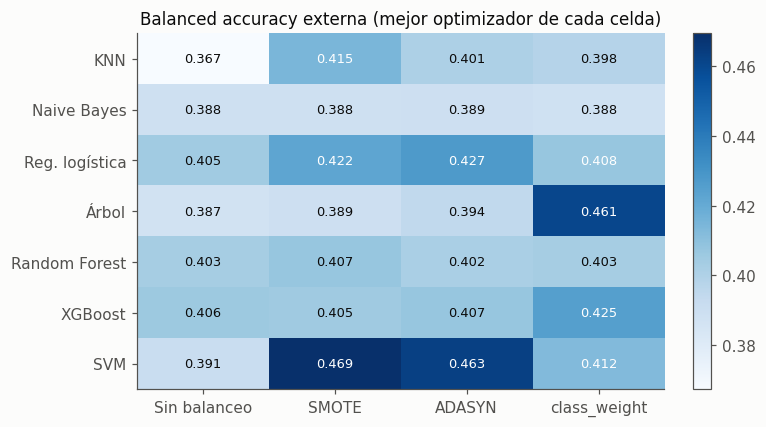

In [3]:
heat = mc.pivot_table(index='model', columns='balance', values='outer_recall_mean', aggfunc='max').reindex(index=MODELS, columns=BALS)
fig, ax = plt.subplots(figsize=(6.8, 4.2))
im = ax.imshow(heat.to_numpy(), cmap='Blues', aspect='auto')
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.iat[i, j]
        ax.text(j, i, f'{v:.3f}', ha='center', va='center', fontsize=8.5,
                color='white' if v > np.nanpercentile(heat.to_numpy(), 70) else P.INK)
ax.set_xticks(range(len(BALS)), [M.PRETTY[b] for b in BALS]); ax.set_yticks(range(len(MODELS)), [M.PRETTY[m] for m in MODELS])
ax.grid(False); ax.set_title('Balanced accuracy externa (mejor optimizador de cada celda)')
plt.colorbar(im, ax=ax, fraction=0.04)
P.save(fig, 'e3_clf_heatmap'); plt.show()

**Interpretación.** Las mejores balanced accuracy anidadas (0,46 a 0,47) son de SVM con SMOTE o ADASYN y del árbol con
`class_weight`, pero vienen con desviaciones de ±0,08 a ±0,11 entre pliegues, el doble que el resto. La
razón está en la sección 9.6: esas combinaciones predicen Fallecimiento para miles de casos, y en un
pliegue con 1 a 4 fallecimientos acertar uno más sube la métrica hasta 0,25. Las combinaciones con mejor
AUC y F1 (logística con SMOTE o ADASYN, XGBoost con `class_weight`) tienen balanced accuracy algo menor
(0,42 a 0,43) pero mucho más estable (±0,05 a ±0,07). En el mapa de calor, el balanceo solo mueve la
métrica de forma apreciable en SVM (+0,07 con SMOTE), KNN (+0,05) y el árbol (+0,07 con `class_weight`);
en Naive Bayes, Random Forest y XGBoost la diferencia entre técnicas es de centésimas.

## 9.2 Mejor combinación de cada modelo en la prueba

Para cada uno de los 7 modelos se toma la combinación (balanceo × optimizador) con mejor
balanced accuracy externa **media** en la validación anidada; la prueba no interviene en la
elección. Además se incluye la regresión logística del entregable 2 (C = 1, L2, sin búsqueda)
como referencia.

In [4]:
best = mc.loc[mc.groupby('model').outer_recall_mean.idxmax()].set_index('model').reindex(MODELS)
best_combo = best.combo.to_dict()
tt = tc.set_index('combo')
probs = {m: F.load('clf', best_combo[m])[0] for m in MODELS}
tm = {m: E.classification_metrics(yt, probs[m]) for m in MODELS}
res = pd.DataFrame({
    'Combinación elegida': [f'{M.PRETTY[best.loc[m, "balance"]]} · {M.PRETTY[best.loc[m, "optimizer"]]}' for m in MODELS],
    'Balanced acc. anidada': [fmt(best.loc[m, 'outer_recall_mean'], best.loc[m, 'outer_recall_std']) for m in MODELS],
    **{k: [tm[m][v] for m in MODELS] for k, v in
       [('Accuracy', 'accuracy'), ('Precision', 'precision'), ('Recall (balanced acc.)', 'recall'),
        ('F1-score', 'f1'), ('AUC', 'auc'), ('Brier', 'brier'), ('ECE', 'ece')]}
}, index=[M.PRETTY[m] for m in MODELS])
res.round(3)

,Combinación elegida,Balanced acc. anidada,Accuracy,Precision,Recall (balanced acc.),F1-score,AUC,Brier,ECE
KNN,SMOTE · Genética,0.415 ± 0.107,0.384,0.408,0.397,0.320,0.624,0.739,0.114
Naive Bayes,ADASYN · Genética,0.389 ± 0.060,0.499,0.384,0.379,0.373,0.690,0.627,0.146
Reg. logística,ADASYN · Bayesiana (TPE),0.427 ± 0.067,0.515,0.393,0.400,0.386,0.699,0.584,0.025
Árbol,class_weight · Bayesiana (TPE),0.461 ± 0.084,0.441,0.387,0.384,0.340,0.628,0.665,0.091
Random Forest,SMOTE · Bayesiana (TPE),0.407 ± 0.060,0.519,0.399,0.399,0.391,0.696,0.598,0.099
XGBoost,class_weight · Bayesiana (TPE),0.425 ± 0.069,0.511,0.404,0.390,0.382,0.688,0.577,0.024
SVM,SMOTE · Random,0.469 ± 0.101,0.479,0.402,0.435,0.366,0.678,0.630,0.068


Precision, recall y F1 son promedios macro de las 4 clases; AUC es el promedio macro de las
curvas una-contra-el-resto. Como referencia, el entregable 2 reportó para su regresión logística
(C = 1, L2, `class_weight='balanced'`, 1.433 columnas, entrenada con todo el desarrollo) un
balanced accuracy de 0,40, F1 macro de 0,40 y AUC macro de 0,69 en esta misma prueba.

**Interpretación.** En la prueba todos los modelos quedan por debajo de su balanced accuracy anidada (0,38 a 0,43 frente a
0,39 a 0,47); la caída es mayor justo en las combinaciones más dependientes de Fallecimiento (SVM de 0,469
a 0,435, árbol de 0,461 a 0,384), consistente con que su ventaja anidada era en parte ruido de esa clase.
El mejor balanced accuracy en la prueba es el de SVM (0,435), pero con F1 macro bajo (0,366). Random Forest,
XGBoost y la logística dan el mejor equilibrio: accuracy de 0,51 a 0,52, F1 macro de 0,38 a 0,39 y AUC de
0,69 a 0,70. Frente al entregable 2 (logística con C = 1 y 1.433 columnas: balanced accuracy 0,40, F1 0,40,
AUC 0,69), **ningún modelo mejora de forma clara**: con estas 9 variables el techo parece estar en torno a
0,40 de balanced accuracy y 0,70 de AUC, y el capítulo 13 contrasta si alguna diferencia es significativa.
KNN y el árbol son los peores en AUC (0,62 a 0,63).

## 9.3 Matrices de confusión

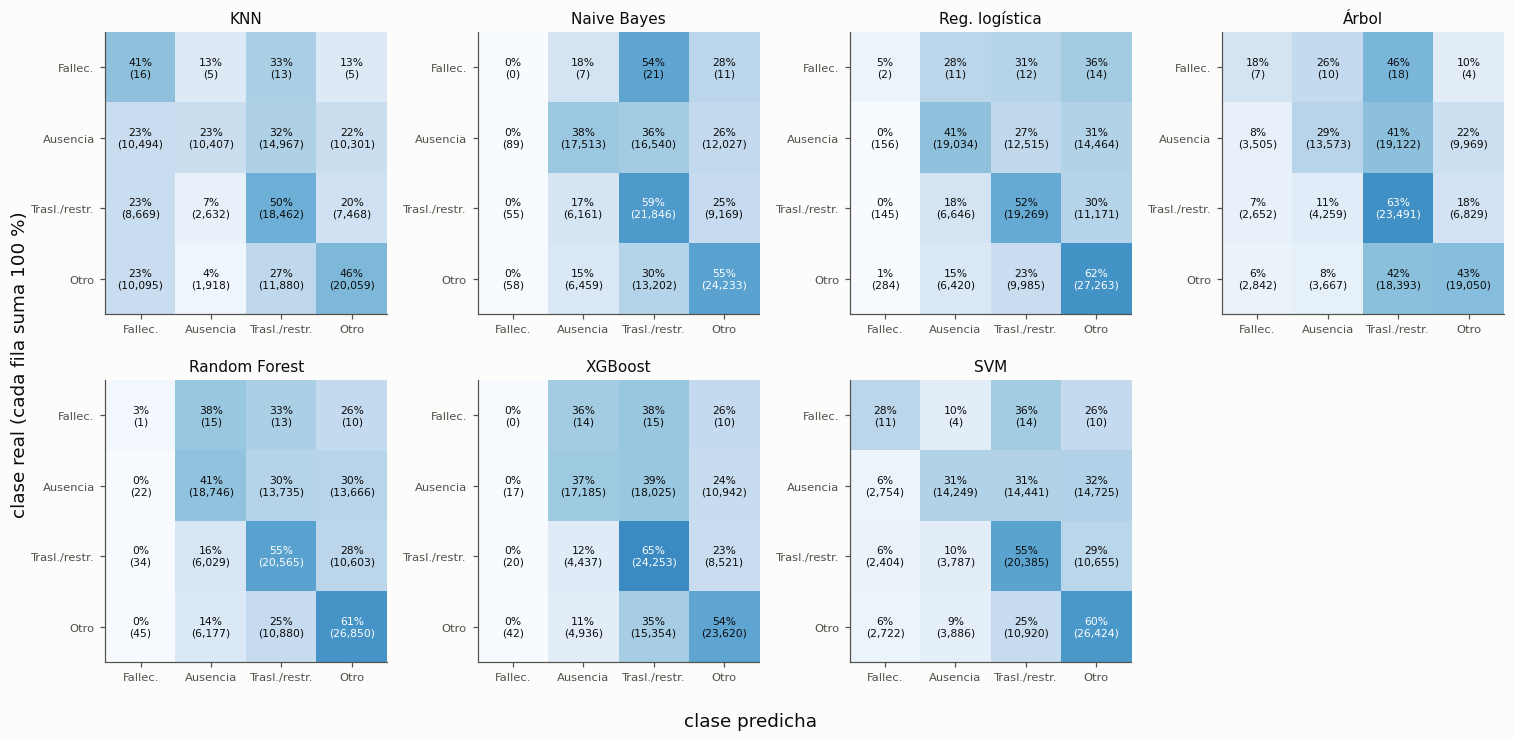

In [5]:
probs = {m: F.load('clf', best_combo[m])[0] for m in MODELS}
fig, axes = plt.subplots(2, 4, figsize=(14, 6.8))
short = ['Fallec.', 'Ausencia', 'Trasl./restr.', 'Otro']
for ax, m in zip(axes.flat, MODELS):
    cm = confusion_matrix(yt, probs[m].argmax(1), labels=range(4))
    pct = cm / cm.sum(axis=1, keepdims=True) * 100
    ax.imshow(pct, cmap='Blues', vmin=0, vmax=100)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f'{pct[i, j]:.0f}%\n({cm[i, j]:,})', ha='center', va='center', fontsize=7,
                    color='white' if pct[i, j] > 55 else P.INK)
    ax.set_xticks(range(4), short, fontsize=7.5); ax.set_yticks(range(4), short, fontsize=7.5)
    ax.set_title(M.PRETTY[m], fontsize=10); ax.grid(False)
axes[1, 3].axis('off')
fig.supxlabel('clase predicha'); fig.supylabel('clase real (cada fila suma 100 %)')
fig.tight_layout(); P.save(fig, 'e3_clf_confusion'); plt.show()

**Interpretación.** Las tres clases frecuentes se confunden entre sí en todos los modelos: la diagonal va del 23 % al 65 %.
«Traslado/restricción» y «otro registrable» se reconocen mejor (50 % a 65 % y 43 % a 62 %) que «días de
ausencia» (23 % a 41 %), igual que en el entregable 2. Fallecimiento muestra el costo del balanceo: KNN con
SMOTE acierta 16 de 39 (41 %) pero manda a esa clase el 23 % de los casos de las demás (más de 29.000
falsos fallecimientos); SVM acierta 11 con unos 7.900 falsos. XGBoost, Random Forest y Naive Bayes casi
nunca predicen Fallecimiento, así que no pagan ese costo, pero tampoco la detectan. Ningún modelo
encuentra una forma de separar los fallecimientos sin sacrificar mucho las demás clases.

## 9.4 Curvas ROC

Una curva por clase (una contra el resto) para cada modelo. La de Fallecimiento se basa en 39
casos y es muy irregular.

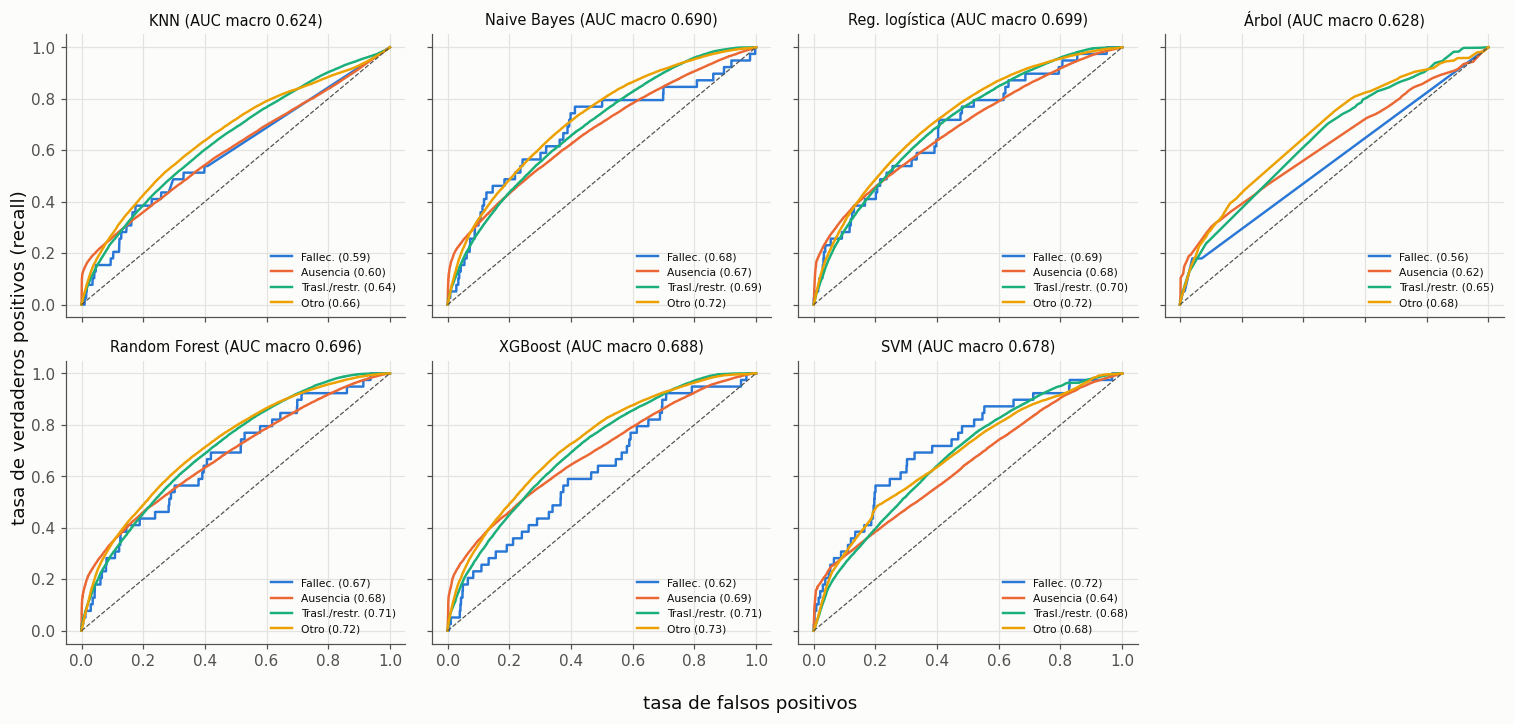

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6.6), sharex=True, sharey=True)
for ax, m in zip(axes.flat, MODELS):
    for k in range(4):
        fpr, tpr, _ = roc_curve(yt == k, probs[m][:, k])
        ax.plot(fpr, tpr, color=P.CLASS_COLORS[k], lw=1.6, label=f'{short[k]} ({roc_auc_score(yt == k, probs[m][:, k]):.2f})')
    ax.plot([0, 1], [0, 1], color=P.INK2, lw=0.8, ls='--')
    ax.set_title(f'{M.PRETTY[m]} (AUC macro {tm[m]["auc"]:.3f})', fontsize=9.5)
    ax.legend(fontsize=7, loc='lower right')
axes[1, 3].axis('off')
fig.supxlabel('tasa de falsos positivos'); fig.supylabel('tasa de verdaderos positivos (recall)')
fig.tight_layout(); P.save(fig, 'e3_clf_roc'); plt.show()

**Interpretación.** Las curvas de las tres clases frecuentes son parecidas entre modelos (AUC de 0,60 a 0,73 por clase); la
mejor separada es «otro registrable» (hasta 0,73 en Random Forest y XGBoost). La curva de Fallecimiento es
irregular por sus 39 casos y su AUC cambia mucho entre combinaciones, de 0,50 (KNN sin balanceo) a 0,72
(SVM con SMOTE, Naive Bayes y Random Forest sin balanceo), sin que eso se traduzca en detectarlos con un
umbral razonable: con 39 positivos, ordenar bien unos pocos casos basta para mover mucho esa AUC. Las AUC macro van de 0,62 (KNN) y 0,63 (árbol) a 0,70 (logística, Random Forest).

## 9.5 Balanceo de clases: con y sin

Diferencia en la validación anidada entre cada técnica y «sin balanceo», con el mismo modelo y el
mismo optimizador (pareado), promediada sobre los 4 optimizadores. Además, el recall por clase
en la prueba del mejor optimizador de cada (modelo, balanceo).

In [7]:
fcl = N.fold_table('clf')
rows = []
for met, lab in [('recall', 'Balanced acc.'), ('f1', 'F1 macro'), ('auc', 'AUC macro'), ('accuracy', 'Accuracy')]:
    pv = fcl.pivot_table(index=['model', 'optimizer', 'fold'], columns='balance', values=f'outer_{met}')
    for b in ['smote', 'adasyn', 'class_weight']:
        d = (pv[b] - pv['none']).groupby(level='model').mean()
        for m, v in d.items():
            rows.append({'métrica': lab, 'modelo': M.PRETTY[m], 'balanceo': M.PRETTY[b], 'Δ vs sin balanceo': v})
delta = pd.DataFrame(rows).pivot_table(index='modelo', columns=['métrica', 'balanceo'], values='Δ vs sin balanceo')
delta = delta.reindex([M.PRETTY[m] for m in MODELS])
delta[['Balanced acc.', 'F1 macro', 'AUC macro', 'Accuracy']].round(3)

métrica        Balanced acc.                     F1 macro                      \
balanceo              ADASYN  SMOTE class_weight   ADASYN  SMOTE class_weight   
modelo                                                                          
KNN                    0.031  0.034        0.009   -0.051 -0.050       -0.016   
Naive Bayes            0.002  0.001        0.001    0.000 -0.001       -0.001   
Reg. logística         0.014  0.002       -0.020   -0.006 -0.006       -0.039   
Árbol                  0.007  0.002        0.045   -0.011 -0.015       -0.025   
Random Forest         -0.001  0.001       -0.000   -0.006 -0.006       -0.007   
XGBoost                0.001  0.000        0.002   -0.003 -0.005       -0.005   
SVM                    0.068  0.052        0.004   -0.004  0.003       -0.018   

métrica        AUC macro                     Accuracy                      
balanceo          ADASYN  SMOTE class_weight   ADASYN  SMOTE class_weight  
modelo                                                                     
KNN                0.011  0.006        0.010   -0.097 -0.101       -0.027  
Naive Bayes        0.005  0.027        0.005    0.003  0.001        0.001  
Reg. logística     0.029  0.031       -0.071   -0.010 -0.009       -0.051  
Árbol             -0.036 -0.027       -0.044   -0.006 -0.015       -0.043  
Random Forest     -0.009 -0.022       -0.019   -0.004 -0.004       -0.006  
XGBoost            0.017  0.016        0.010   -0.003 -0.004       -0.010  
SVM                0.015  0.024       -0.007   -0.014 -0.006       -0.034

In [8]:
rec = []
for m in MODELS:
    for b in BALS:
        sub = mc[(mc.model == m) & (mc.balance == b)]
        combo = sub.loc[sub.outer_recall_mean.idxmax(), 'combo']
        p = F.load('clf', combo)[0].argmax(1)
        r = classification_report(yt, p, labels=range(4), output_dict=True, zero_division=0)
        rec.append({'modelo': M.PRETTY[m], 'balanceo': M.PRETTY[b], **{f'recall {short[k]}': r[str(k)]['recall'] for k in range(4)},
                    'fallecimientos detectados (de 39)': int(((p == 0) & (yt == 0)).sum()),
                    'casos predichos como fallecimiento': int((p == 0).sum())})
pd.DataFrame(rec).set_index(['modelo', 'balanceo']).round(3)

recall Fallec.  recall Ausencia  \
modelo         balanceo                                        
KNN            Sin balanceo           0.000            0.466   
               SMOTE                  0.410            0.225   
               ADASYN                 0.154            0.258   
               class_weight           0.128            0.312   
Naive Bayes    Sin balanceo           0.077            0.379   
               SMOTE                  0.000            0.384   
               ADASYN                 0.000            0.379   
               class_weight           0.026            0.378   
Reg. logística Sin balanceo           0.000            0.495   
               SMOTE                  0.179            0.390   
               ADASYN                 0.051            0.412   
               class_weight           0.154            0.327   
Árbol          Sin balanceo           0.000            0.446   
               SMOTE                  0.051            0.393   
               ADASYN                 0.026            0.398   
               class_weight           0.179            0.294   
Random Forest  Sin balanceo           0.000            0.478   
               SMOTE                  0.026            0.406   
               ADASYN                 0.026            0.345   
               class_weight           0.051            0.370   
XGBoost        Sin balanceo           0.000            0.483   
               SMOTE                  0.000            0.369   
               ADASYN                 0.000            0.407   
               class_weight           0.000            0.372   
SVM            Sin balanceo           0.051            0.568   
               SMOTE                  0.282            0.309   
               ADASYN                 0.282            0.328   
               class_weight           0.282            0.496   

                             recall Trasl./restr.  recall Otro  \
modelo         balanceo                                          
KNN            Sin balanceo                 0.457        0.525   
               SMOTE                        0.496        0.456   
               ADASYN                       0.605        0.519   
               class_weight                 0.565        0.493   
Naive Bayes    Sin balanceo                 0.583        0.547   
               SMOTE                        0.589        0.549   
               ADASYN                       0.587        0.551   
               class_weight                 0.587        0.546   
Reg. logística Sin balanceo                 0.446        0.602   
               SMOTE                        0.538        0.530   
               ADASYN                       0.518        0.620   
               class_weight                 0.475        0.583   
Árbol          Sin balanceo                 0.392        0.674   
               SMOTE                        0.465        0.631   
               ADASYN                       0.576        0.522   
               class_weight                 0.631        0.433   
Random Forest  Sin balanceo                 0.508        0.584   
               SMOTE                        0.552        0.611   
               ADASYN                       0.678        0.506   
               class_weight                 0.627        0.553   
XGBoost        Sin balanceo                 0.482        0.591   
               SMOTE                        0.676        0.490   
               ADASYN                       0.585        0.565   
               class_weight                 0.651        0.537   
SVM            Sin balanceo                 0.309        0.584   
               SMOTE                        0.548        0.601   
               ADASYN                       0.389        0.671   
               class_weight                 0.302        0.468   

                             fallecimientos detectados (de 39)  \
modelo         balanceo                                      

**Interpretación.** El balanceo **no es gratis**. Pareado por modelo, optimizador y pliegue: SMOTE y ADASYN suben el
balanced accuracy en KNN (+0,03) y sobre todo en SVM (+0,05 a +0,07), pero bajan el F1 macro (−0,05 en
KNN) y el accuracy (−0,10 en KNN). `class_weight` sube el balanced accuracy del árbol (+0,045) a costa de
AUC (−0,044) y accuracy (−0,043), y en la logística lo empeora todo (−0,02 en balanced accuracy y −0,07
en AUC). En Naive Bayes, Random Forest y XGBoost el efecto es de milésimas. La tabla de la prueba muestra
el mecanismo: el balanceo cambia sobre todo el recall de Fallecimiento y lo paga con recall de «días de
ausencia» (KNN pasa de 0,47 a 0,23 con SMOTE). La técnica «óptima» depende de la métrica que se elija,
y con balanced accuracy la elección queda dominada por una clase de 39 casos.

## 9.6 Tratamiento de la clase Fallecimiento

Corrección del entregable 1: el profesor señaló que la clase Fallecimiento quedó sin tratamiento.
En este entregable se trata con las tres técnicas de balanceo de la guía (SMOTE, ADASYN y
`class_weight`) y se mide su efecto con intervalos, porque con 39 casos en la prueba cualquier
recall es muy incierto. Intervalo de Wilson al 95 % para el recall (aciertos de 39) y para la
precisión (aciertos entre los casos predichos como fallecimiento).

Además, el balanced accuracy promedia el recall de las 4 clases: acertar **un** fallecimiento más de
39 sube la métrica 0,25/39 ≈ 0,006, y en un pliegue externo con 1 fallecimiento la sube 0,25. Por eso
se reporta también el balanced accuracy de las **3 clases frecuentes** (sin Fallecimiento), que es
mucho más estable.

In [9]:
def wilson(k, n, z=1.959964):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n; den = 1 + z * z / n; c = (p + z * z / (2 * n)) / den; h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (c - h, c + h)
rows = []
for m in MODELS:
    for b in BALS:
        sub = mc[(mc.model == m) & (mc.balance == b)]
        combo = sub.loc[sub.outer_recall_mean.idxmax(), 'combo']
        pr = F.load('clf', combo)[0]; pred = pr.argmax(1)
        hits, n_pred, n_true = int(((pred == 0) & (yt == 0)).sum()), int((pred == 0).sum()), int((yt == 0).sum())
        rlo, rhi = wilson(hits, n_true); plo, phi = wilson(hits, n_pred)
        rec = [((pred == k) & (yt == k)).sum() / (yt == k).sum() for k in range(4)]
        rows.append({'modelo': M.PRETTY[m], 'balanceo': M.PRETTY[b], 'aciertos (de 39)': hits, 'predichos como fallec.': n_pred,
                     'recall fallec.': hits / n_true, 'IC Wilson recall': f'[{rlo:.3f}, {rhi:.3f}]',
                     'precisión fallec.': hits / n_pred if n_pred else np.nan,
                     'IC Wilson precisión': f'[{plo:.4f}, {phi:.4f}]' if n_pred else '—',
                     'AUC fallec. (1 vs resto)': roc_auc_score(yt == 0, pr[:, 0]),
                     'balanced acc. (4 clases)': np.mean(rec), 'balanced acc. (3 clases frecuentes)': np.mean(rec[1:])})
death = pd.DataFrame(rows).set_index(['modelo', 'balanceo'])
death.round(4)

aciertos (de 39)  predichos como fallec.  \
modelo         balanceo                                                 
KNN            Sin balanceo                 0                       0   
               SMOTE                       16                   29274   
               ADASYN                       6                    8707   
               class_weight                 5                    8635   
Naive Bayes    Sin balanceo                 3                    1591   
               SMOTE                        0                     201   
               ADASYN                       0                     202   
               class_weight                 1                    1342   
Reg. logística Sin balanceo                 0                       0   
               SMOTE                        7                    5325   
               ADASYN                       2                     587   
               class_weight                 6                    5325   
Árbol          Sin balanceo                 0                       0   
               SMOTE                        2                     914   
               ADASYN                       1                     894   
               class_weight                 7                    9006   
Random Forest  Sin balanceo                 0                       0   
               SMOTE                        1                     102   
               ADASYN                       1                      79   
               class_weight                 2                     687   
XGBoost        Sin balanceo                 0                       0   
               SMOTE                        0                      38   
               ADASYN                       0                      23   
               class_weight                 0                      79   
SVM            Sin balanceo                 2                     444   
               SMOTE                       11                    7891   
               ADASYN                      11                    8174   
               class_weight                11                    9571   

                             recall fallec. IC Wilson recall  \
modelo         balanceo                                        
KNN            Sin balanceo          0.0000   [0.000, 0.090]   
               SMOTE                 0.4103   [0.271, 0.566]   
               ADASYN                0.1538   [0.072, 0.297]   
               class_weight          0.1282   [0.056, 0.267]   
Naive Bayes    Sin balanceo          0.0769   [0.027, 0.203]   
               SMOTE                 0.0000   [0.000, 0.090]   
               ADASYN                0.0000   [0.000, 0.090]   
               class_weight          0.0256   [0.005, 0.132]   
Reg. logística Sin balanceo          0.0000   [0.000, 0.090]   
               SMOTE                 0.1795   [0.090, 0.327]   
               ADASYN                0.0513   [0.014, 0.169]   
               class_weight          0.1538   [0.072, 0.297]   
Árbol          Sin balanceo          0.0000   [0.000, 0.090]   
               SMOTE                 0.0513   [0.014, 0.169]   
               ADASYN                0.0256   [0.005, 0.132]   
               class_weight          0.1795   [0.090, 0.327]   
Random Forest  Sin balanceo          0.0000   [0.000, 0.090]   
               SMOTE                 0.0256   [0.005, 0.132]   
               ADASYN                0.0256   [0.005, 0.132]   
               class_weight          0.0513   [0.014, 0.169]   
XGBoost        Sin balanceo          0.0000   [0.000, 0.090]   
               SMOTE                 0.0000   [0.000, 0.090]   
               ADASYN                0.0000   [0.000, 0.090]   
               class_weight          0.0000   [0.000, 0.090]   
SVM            Sin balanceo          0.0513   [0.014, 0.169]   
               SMOTE                 0.2821   [0.165, 0.438]   
               ADASYN                0.2821   

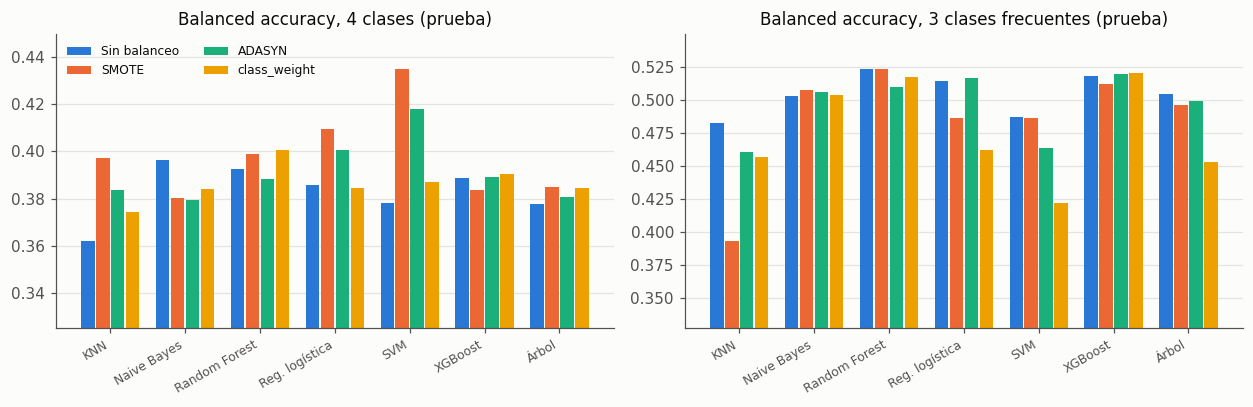

In [10]:
ba3 = death['balanced acc. (3 clases frecuentes)'].unstack('balanceo')[[M.PRETTY[b] for b in BALS]]
ba4 = death['balanced acc. (4 clases)'].unstack('balanceo')[[M.PRETTY[b] for b in BALS]]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), sharey=False)
for ax, tab, title in [(axes[0], ba4, 'Balanced accuracy, 4 clases (prueba)'), (axes[1], ba3, 'Balanced accuracy, 3 clases frecuentes (prueba)')]:
    x = np.arange(len(tab)); w = 0.2
    for j, b in enumerate(BALS):
        ax.bar(x + (j - 1.5) * w, tab[M.PRETTY[b]], width=w - 0.02, color=P.BAL_COLORS[b], label=M.PRETTY[b])
    ax.set_xticks(x, tab.index, rotation=30, ha='right', fontsize=8); ax.set_title(title)
    lo, hi = np.nanmin(tab.to_numpy()), np.nanmax(tab.to_numpy()); ax.set_ylim(lo - (hi - lo) * 0.5, hi + (hi - lo) * 0.2)
    ax.grid(axis='x', visible=False)
axes[0].legend(fontsize=8, ncol=2)
fig.tight_layout(); P.save(fig, 'e3_clf_death_ba3'); plt.show()

**Interpretación.** **Fallecimiento sigue sin poder detectarse de forma útil.** La mejor detección es la de KNN con SMOTE:
16 de 39 (recall 0,41, IC de Wilson [0,27; 0,57]), con una precisión del 0,05 % (16 aciertos entre 29.274
casos marcados). SVM con cualquiera de las tres técnicas acierta 11 (0,28, [0,17; 0,44]) con unos 8.000 a
9.600 casos marcados. Sin balanceo casi ningún modelo predice esa clase. Es decir, el tratamiento
funciona en el sentido de la métrica (sube el recall), pero no produce un detector utilizable: por cada
fallecimiento encontrado hay más de 700 falsas alarmas.

El balanced accuracy de las **3 clases frecuentes** cuenta otra historia y cambia el ordenamiento:
Random Forest (0,52), XGBoost (0,52) y la logística sin balanceo o con ADASYN (0,51 a 0,52) quedan
arriba, mientras que las combinaciones que «ganaban» con 4 clases caen: KNN con SMOTE baja a 0,39 (sin
balanceo tenía 0,48) y SVM con `class_weight` a 0,42. El balanceo agresivo quita aciertos en las clases
frecuentes para dárselos a Fallecimiento. Por eso las conclusiones del informe se apoyan en las dos
métricas y en AUC/F1, y no solo en el balanced accuracy de 4 clases. La misma conclusión aparece en la
corrida con diseño temporal (sección 12.6): su mejor balanced accuracy (0,52) viene de acertar 8 de 12
fallecimientos marcando 5.337 casos.

## 9.7 Calibración de probabilidades

- **Brier multiclase:** media de Σₖ (pₖ − 1[y = k])²; 0 es perfecto. El Dummy que predice las
  frecuencias de la prueba obtendría ≈ 0,664 (entregable 2).
- **ECE:** con 15 intervalos de la confianza de la clase predicha, promedio ponderado de
  |accuracy − confianza|.
- **Diagrama de confiabilidad:** confianza predicha frente a la frecuencia observada de acierto,
  y para la clase «días de ausencia», probabilidad predicha frente a la frecuencia real.

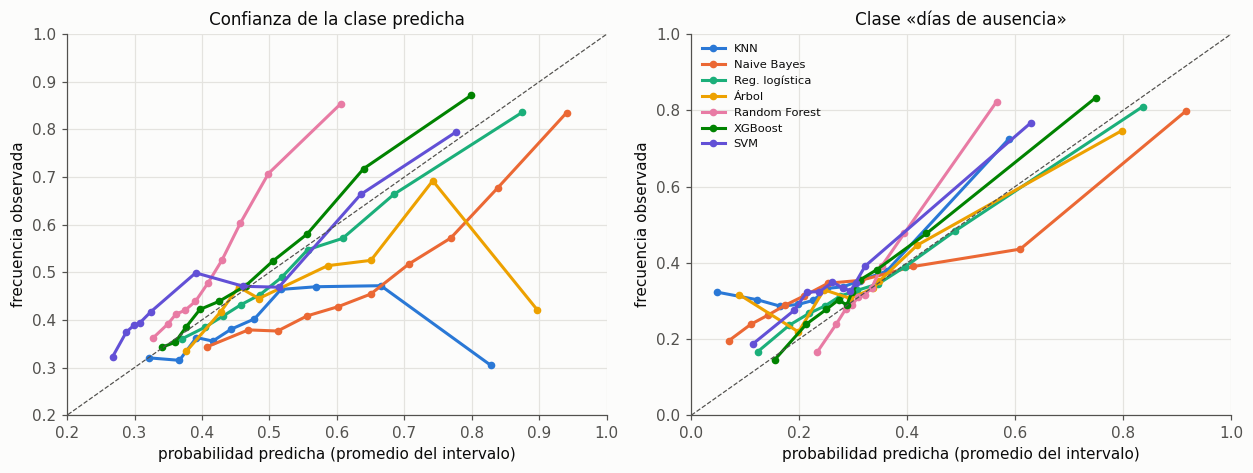

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
for i, m in enumerate(MODELS):
    p = probs[m]
    conf = p.max(1); correct = (p.argmax(1) == yt)
    fo, mp = calibration_curve(correct, conf, n_bins=10, strategy='quantile')
    axes[0].plot(mp, fo, marker='o', ms=4, color=P.MODEL_COLORS[m], label=M.PRETTY[m])
    fo2, mp2 = calibration_curve(yt == 1, p[:, 1], n_bins=10, strategy='quantile')
    axes[1].plot(mp2, fo2, marker='o', ms=4, color=P.MODEL_COLORS[m], label=M.PRETTY[m])
for ax, t in zip(axes, ['Confianza de la clase predicha', 'Clase «días de ausencia»']):
    ax.plot([0, 1], [0, 1], ls='--', color=P.INK2, lw=0.8)
    ax.set_xlabel('probabilidad predicha (promedio del intervalo)'); ax.set_ylabel('frecuencia observada'); ax.set_title(t)
axes[0].set_xlim(0.2, 1); axes[0].set_ylim(0.2, 1); axes[1].set_xlim(0, 1); axes[1].set_ylim(0, 1)
axes[1].legend(fontsize=7.5, loc='upper left')
fig.tight_layout(); P.save(fig, 'e3_clf_calibracion'); plt.show()

### Recalibración (Platt e isotónica)

Para cada uno de los 7 modelos se reajusta el pipeline dentro de `CalibratedClassifierCV` con 3
pliegues por establecimiento de la submuestra de desarrollo: en cada pliegue se entrena el modelo
con dos tercios y se ajusta el calibrador (sigmoide de Platt o regresión isotónica, una contra el
resto y luego normalizada) con el tercio restante. Así el calibrador nunca ve la prueba.

In [12]:
from sklearn.model_selection import StratifiedGroupKFold
def run_recal():
    X, y, g, s = N.task_data('clf')
    folds = list(StratifiedGroupKFold(3, shuffle=True, random_state=C.seed_for('inner', 99)).split(X, y, g))
    rows, curves = [], {}
    for m in MODELS:
        r = best.loc[m]
        params = json.loads(r.final_params)
        rows.append({'modelo': M.PRETTY[m], 'método': 'sin recalibrar', **E.classification_metrics(yt, probs[m])})
        for method in ['sigmoid', 'isotonic']:
            pipe = M.make_pipeline('clf', m, params, r.balance, C.SEED)
            cal = CalibratedClassifierCV(pipe, method=method, cv=folds, n_jobs=3)
            with warnings.catch_warnings():
                warnings.simplefilter('ignore'); cal.fit(X, y)
            p = cal.predict_proba(test[D.FEATURES])
            rows.append({'modelo': M.PRETTY[m], 'método': 'Platt (sigmoide)' if method == 'sigmoid' else 'isotónica',
                         **E.classification_metrics(yt, p)})
            curves[(m, method)] = calibration_curve(p.argmax(1) == yt, p.max(1), n_bins=10, strategy='quantile')
    return pd.DataFrame(rows), curves
recal, recal_curves = cache.cached('clf_recalibration', run_recal)
recal.set_index(['modelo', 'método'])[['brier', 'ece', 'log_loss', 'recall', 'auc']].round(4)

brier     ece  log_loss  recall     auc
modelo         método                                                    
KNN            sin recalibrar    0.7387  0.1143    1.3673  0.3970  0.6240
               Platt (sigmoide)  0.6192  0.0590    1.0315  0.3354  0.6564
               isotónica         0.6137  0.0483    1.0242  0.3396  0.6546
Naive Bayes    sin recalibrar    0.6271  0.1459    1.0837  0.3794  0.6898
               Platt (sigmoide)  0.5928  0.0353    0.9949  0.3776  0.6655
               isotónica         0.5853  0.0214    0.9799  0.3778  0.6843
Reg. logística sin recalibrar    0.5840  0.0246    0.9831  0.4003  0.6993
               Platt (sigmoide)  0.5942  0.0610    0.9937  0.3851  0.6963
               isotónica         0.5933  0.0574    0.9945  0.3869  0.6841
Árbol          sin recalibrar    0.6650  0.0914    1.1374  0.3845  0.6277
               Platt (sigmoide)  0.5993  0.0544    1.0035  0.3531  0.6771
               isotónica         0.5965  0.0452    0.9976  0.3673  0.6881
Random Forest  sin recalibrar    0.5979  0.0990    1.0185  0.3987  0.6965
               Platt (sigmoide)  0.5766  0.0279    0.9681  0.3903  0.7014
               isotónica         0.5758  0.0236    0.9656  0.3911  0.6993
XGBoost        sin recalibrar    0.5766  0.0243    0.9962  0.3903  0.6878
               Platt (sigmoide)  0.5759  0.0173    0.9674  0.3869  0.6885
               isotónica         0.5730  0.0078    0.9628  0.3916  0.6889
SVM            sin recalibrar    0.6296  0.0676    1.1332  0.4349  0.6782
               Platt (sigmoide)  0.6100  0.0733    1.0201  0.3380  0.6885
               isotónica         0.5918  0.0400    0.9937  0.3773  0.6934

**Interpretación.** - **Bien calibrados sin hacer nada:** XGBoost (ECE 0,024) y la logística (0,025). Sus curvas siguen la
  diagonal.
- **Mal calibrados:** Naive Bayes (ECE 0,146) es sobreconfiado, como se espera por el supuesto de
  independencia (las variables de un mismo lugar de trabajo están correlacionadas y el modelo cuenta la
  misma evidencia varias veces). KNN (0,114) y el árbol (0,091) producen probabilidades extremas en pocas
  hojas o vecindarios. Random Forest con SMOTE es **subconfiado** (su curva va por encima de la
  diagonal): el bosque promedia árboles y el sobremuestreo aplana las probabilidades.
- **Recalibración:** la isotónica baja el ECE de Naive Bayes de 0,146 a 0,021, el de Random Forest de 0,099
  a 0,024, el de KNN de 0,114 a 0,048 y el del árbol de 0,091 a 0,045, y mejora el Brier en todos ellos. En
  la logística y en XGBoost, ya calibrados, recalibrar no ayuda (el ECE de la logística sube de 0,025 a
  0,057 porque el calibrador se ajusta con un tercio de la submuestra). Recalibrar baja el balanced
  accuracy de los modelos balanceados (SVM de 0,435 a 0,338 con Platt): las probabilidades calibradas
  devuelven a Fallecimiento su frecuencia real y el argmax deja de elegirla. Si el uso final requiere
  probabilidades confiables, conviene XGBoost o un Random Forest recalibrado con regresión isotónica.

## 9.8 Segunda prueba: mismos establecimientos, meses nuevos

Corrección del entregable 1 (costo del diseño; ver sección 4.7). Los 83.912 casos de octubre a
diciembre de los establecimientos de **desarrollo** quedaban descartados. Aquí se usan como una
segunda prueba que solo separa por tiempo: el modelo ya vio esos establecimientos (en enero a
septiembre), pero no esos meses. La diferencia con la prueba principal (establecimientos nuevos)
mide cuánto cuesta, en desempeño, exigir que el modelo generalice a lugares que no conoce. Se usan
los mismos 7 modelos, reajustados sobre la misma submuestra de desarrollo.

In [13]:
from osha_e3 import data as D
df_all = D.load_prepared()
dev_est = set(df_all.loc[df_all.split.eq('development'), 'establishment_id'])
temporal = df_all[df_all.establishment_id.isin(dev_est) & df_all.date.ge('2023-10-01')].reset_index(drop=True)
y_tmp = temporal.y_clf.to_numpy() - 1
print(f'Segunda prueba: {len(temporal):,} casos, {temporal.establishment_id.nunique():,} establecimientos, '
      f'{(y_tmp == 0).sum()} fallecimientos')
def run_temporal():
    X, y, _, _ = N.task_data('clf')
    out = {}
    for m in MODELS:
        r = best.loc[m]
        pipe = S.refit('clf', m, json.loads(r.final_params), r.balance, X, y, C.SEED)
        out[m] = pipe.predict_proba(temporal[D.FEATURES])
    return out
p_tmp = cache.cached('clf_temporal_only', run_temporal)
rows = []
for m in MODELS:
    a = E.classification_metrics(yt, probs[m]); b = E.classification_metrics(y_tmp, p_tmp[m])
    rows.append({'modelo': M.PRETTY[m], 'balanced acc. (establ. nuevos)': a['recall'], 'balanced acc. (mismos establ.)': b['recall'],
                 'AUC (establ. nuevos)': a['auc'], 'AUC (mismos establ.)': b['auc'],
                 'accuracy (establ. nuevos)': a['accuracy'], 'accuracy (mismos establ.)': b['accuracy']})
tmp_tab = pd.DataFrame(rows).set_index('modelo')
tmp_tab['Δ AUC (mismos − nuevos)'] = tmp_tab['AUC (mismos establ.)'] - tmp_tab['AUC (establ. nuevos)']
tmp_tab.round(4)

Segunda prueba: 83,912 casos, 20,582 establecimientos, 25 fallecimientos


,balanced acc. (establ. nuevos),balanced acc. (mismos establ.),AUC (establ. nuevos),AUC (mismos establ.),accuracy (establ. nuevos),accuracy (mismos establ.),Δ AUC (mismos − nuevos)
modelo,,,,,,,
KNN,0.3970,0.4774,0.6240,0.6701,0.3842,0.3885,0.0461
Naive Bayes,0.3794,0.3809,0.6898,0.6935,0.4992,0.5010,0.0036
Reg. logística,0.4003,0.4191,0.6993,0.7074,0.5147,0.5170,0.0081
Árbol,0.3845,0.4088,0.6277,0.6390,0.4405,0.4405,0.0113
Random Forest,0.3987,0.3962,0.6965,0.7246,0.5194,0.5243,0.0282
XGBoost,0.3903,0.3919,0.6878,0.6993,0.5107,0.5138,0.0115
SVM,0.4349,0.4557,0.6782,0.6920,0.4794,0.4818,0.0138


**Interpretación.** En la segunda prueba (mismos establecimientos, octubre–diciembre; 83.912 casos, 25 fallecimientos), el
AUC sube en todos los modelos, entre 0,004 (Naive Bayes) y 0,046 (KNN). El accuracy cambia muy poco (≤ 0,005).
El modelo que más gana es KNN (balanced accuracy de 0,40 a 0,48): sus vecinos más cercanos son casos del
mismo establecimiento, que comparten códigos de sector, ocupación y estado, y heredan sus prácticas de
registro. Esto cuantifica el costo de la partición: exigir establecimientos nuevos le cuesta a la mayoría
de los modelos entre 0,004 y 0,03 de AUC. Un diseño que mezclara establecimientos habría reportado esas
cifras más altas sin que el modelo generalizara mejor a lugares nuevos, que es el uso que interesa.
El costo de descartar casos (sección 4.7) es, entonces, una diferencia pequeña en las métricas a cambio de
una estimación honesta.